In [8]:
import warnings
warnings.filterwarnings("ignore")

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
def plot_fig(data, x, y, xlabel, ylabel, title):
    plt.figure(figsize=(14, 5))
    plt.plot(
        data[x],
        data[y]
    )

    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [11]:
# get snow data
snow = pd.read_excel(
    r"C:\Users\katel\extreme climate\data\snow\snotel.xlsx"
)

In [12]:
# review stations
snow[['Location', 'Elevation']].drop_duplicates()

,Location,Elevation
0,Fremont Pass,11310
16870,Copper Mountain,10500
34406,Mesa Lakes,10160
49043,Grizzly Peak,11110


In [13]:
# Inspect
snow.head()

,Date,Snow Water Equivalent (in) Start of Day Values,Precipitation Accumulation (in) Start of Day Values,Air Temperature Maximum (degF),Air Temperature Minimum (degF),Air Temperature Average (degF),Precipitation Increment (in),Location,Elevation
0,1980-07-28,0.0,24.1,NaN,NaN,NaN,0.0,Fremont Pass,11310
1,1980-07-29,0.0,24.1,NaN,NaN,NaN,0.0,Fremont Pass,11310
2,1980-07-30,0.0,24.1,NaN,NaN,NaN,0.0,Fremont Pass,11310
3,1980-07-31,0.0,24.1,NaN,NaN,NaN,0.0,Fremont Pass,11310
4,1980-08-01,0.0,24.1,NaN,NaN,NaN,0.0,Fremont Pass,11310


In [14]:
# convert to date
snow['Date'] = pd.to_datetime(snow['Date'])

In [15]:
# filter columns
snow = snow[[
    'Date',
    'Snow Water Equivalent (in) Start of Day Values',
    'Precipitation Accumulation (in) Start of Day Values',
    'Precipitation Increment (in)',
    'Location',
    'Elevation'
]]

In [16]:
# rename columns
snow = snow.rename(columns={
    'Date': 'date',
    'Snow Water Equivalent (in) Start of Day Values': 'swe',
    'Precipitation Accumulation (in) Start of Day Values': 'precip_accum',
    'Precipitation Increment (in)': 'precip_increment',
    'Location': 'station',
    'Elevation': 'elevation'
})

In [17]:
# inspect
snow.head()

,date,swe,precip_accum,precip_increment,station,elevation
0,1980-07-28,0.0,24.1,0.0,Fremont Pass,11310
1,1980-07-29,0.0,24.1,0.0,Fremont Pass,11310
2,1980-07-30,0.0,24.1,0.0,Fremont Pass,11310
3,1980-07-31,0.0,24.1,0.0,Fremont Pass,11310
4,1980-08-01,0.0,24.1,0.0,Fremont Pass,11310


station
Copper Mountain    100.0
Fremont Pass        96.4
Grizzly Peak        96.2
Mesa Lakes          83.4
dtype: float64


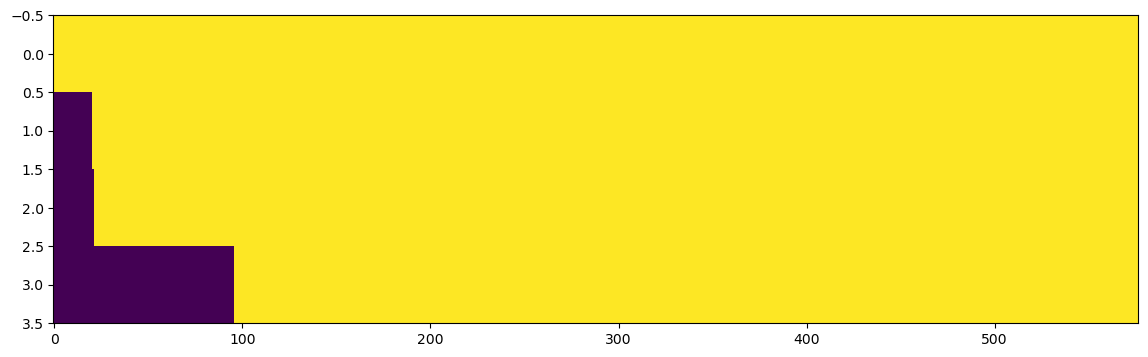

In [18]:
# review of data by month from 4 stations in the colorado river headwaters regions
snow['month'] = snow['date'].dt.to_period('M').dt.to_timestamp()

# group by 
monthly = (
    snow.groupby(['station', 'month'])['swe']
        .apply(lambda x: x.notna().any())
        .unstack(fill_value=False)
        .astype(int)
)

plt.figure(figsize=(14, 4))

plt.imshow(
    monthly,
    aspect='auto',
    interpolation='none'
)

coverage = monthly.mean(axis=1) * 100

print(
    coverage
    .sort_values(ascending=False)
    .round(1)
)

In [19]:
snow['date'] = pd.to_datetime(snow['date'])

In [20]:
# Limit date to 1990-present
recent = snow[
    snow['date'] >= '1990-01-01'
]

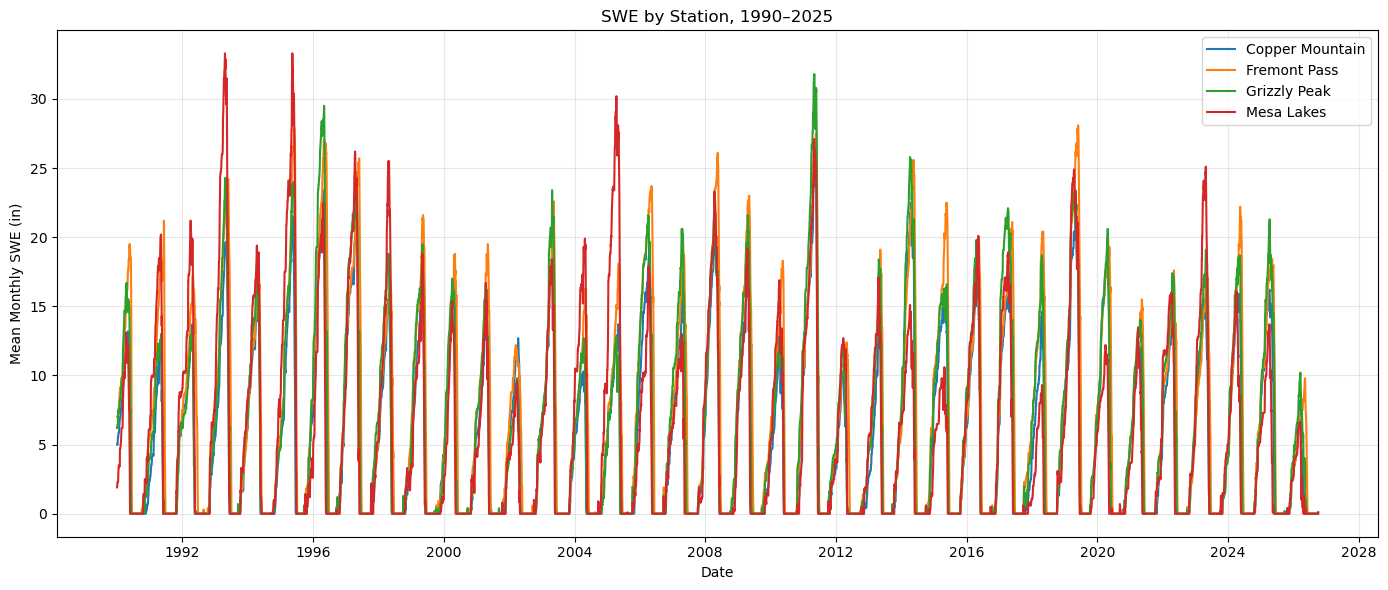

<Figure size 640x480 with 0 Axes>

In [27]:
# Plot swe by station
plt.figure(figsize=(14, 6))

for station, group in recent.groupby('station'):
    plt.plot(
        group['date'],
        group['swe'],
        label=station
    )

plt.xlabel('Date')
plt.ylabel('Mean Monthly SWE (in)')
plt.title('SWE by Station, 1990–2025')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.savefig(
    "figures/swe_by_station_1990_2025.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()

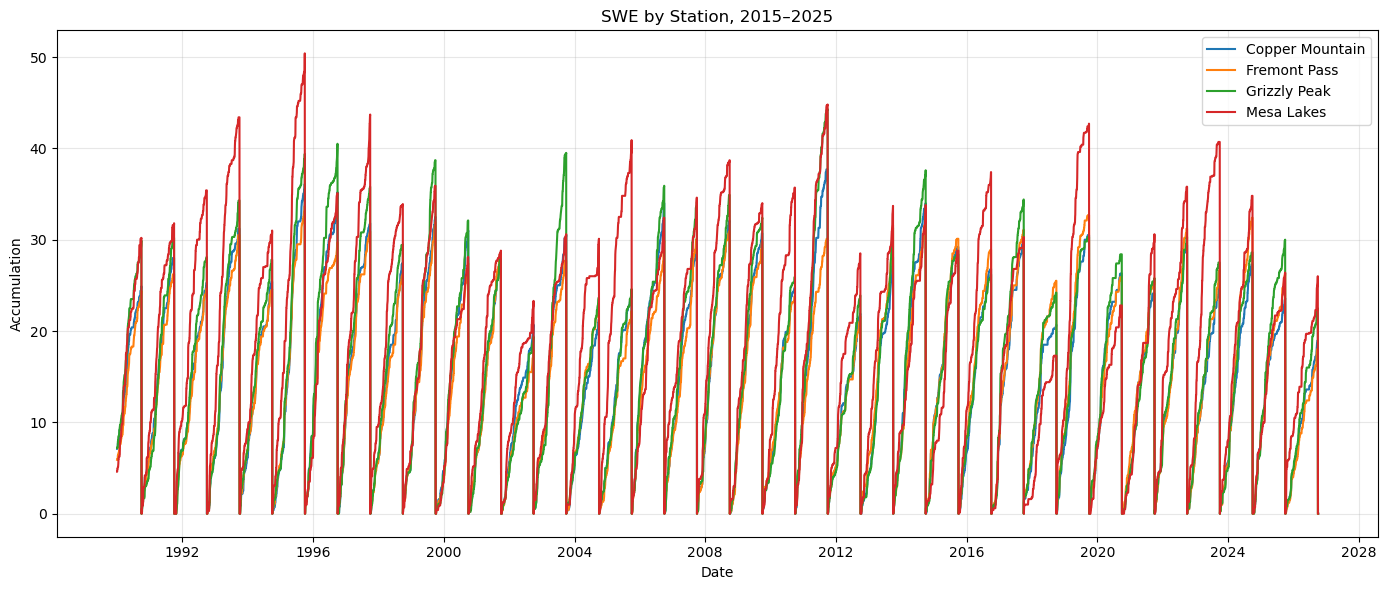

In [22]:
# plot accumulation by station
plt.figure(figsize=(14, 6))

for station, group in recent.groupby('station'):
    plt.plot(
        group['date'],
        group['precip_accum'],
        label=station
    )

plt.xlabel('Date')
plt.ylabel('Accumulation')
plt.title('Accumulation by Station, 1990–2025')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

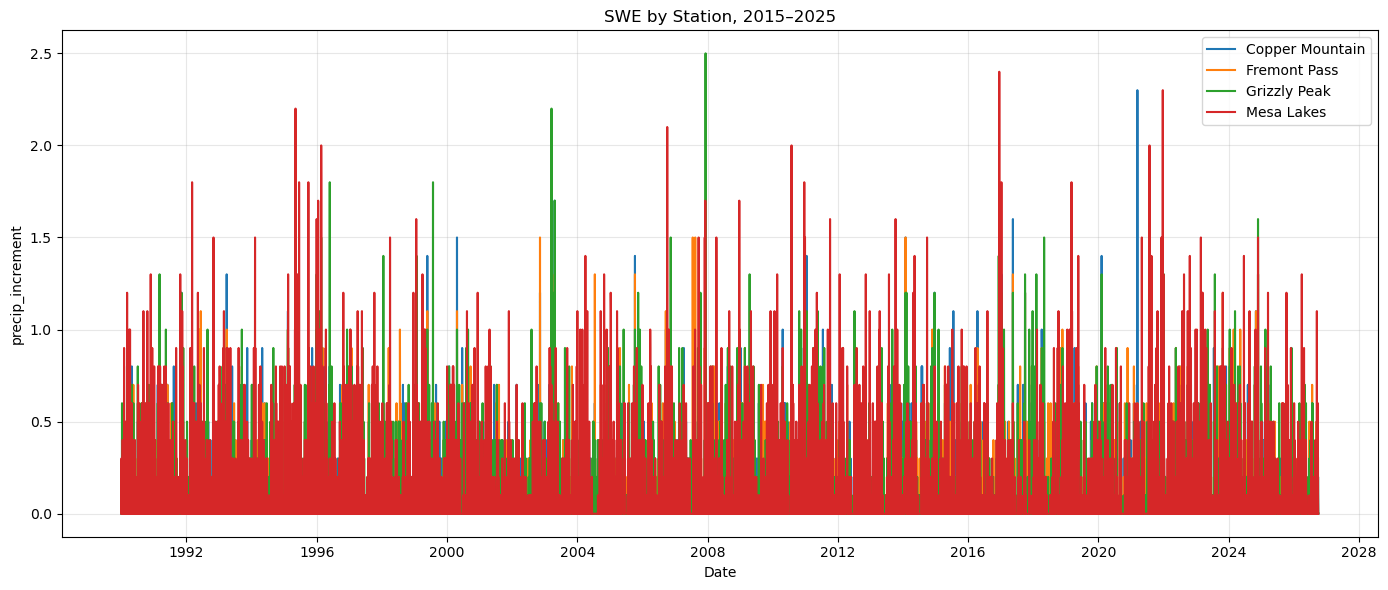

In [23]:
# Plot accumulation increment by station
plt.figure(figsize=(14, 6))

for station, group in recent.groupby('station'):
    plt.plot(
        group['date'],
        group['precip_increment'],
        label=station
    )

plt.xlabel('Date')
plt.ylabel('precip_increment')
plt.title('SWE by Station, 2015–2025')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

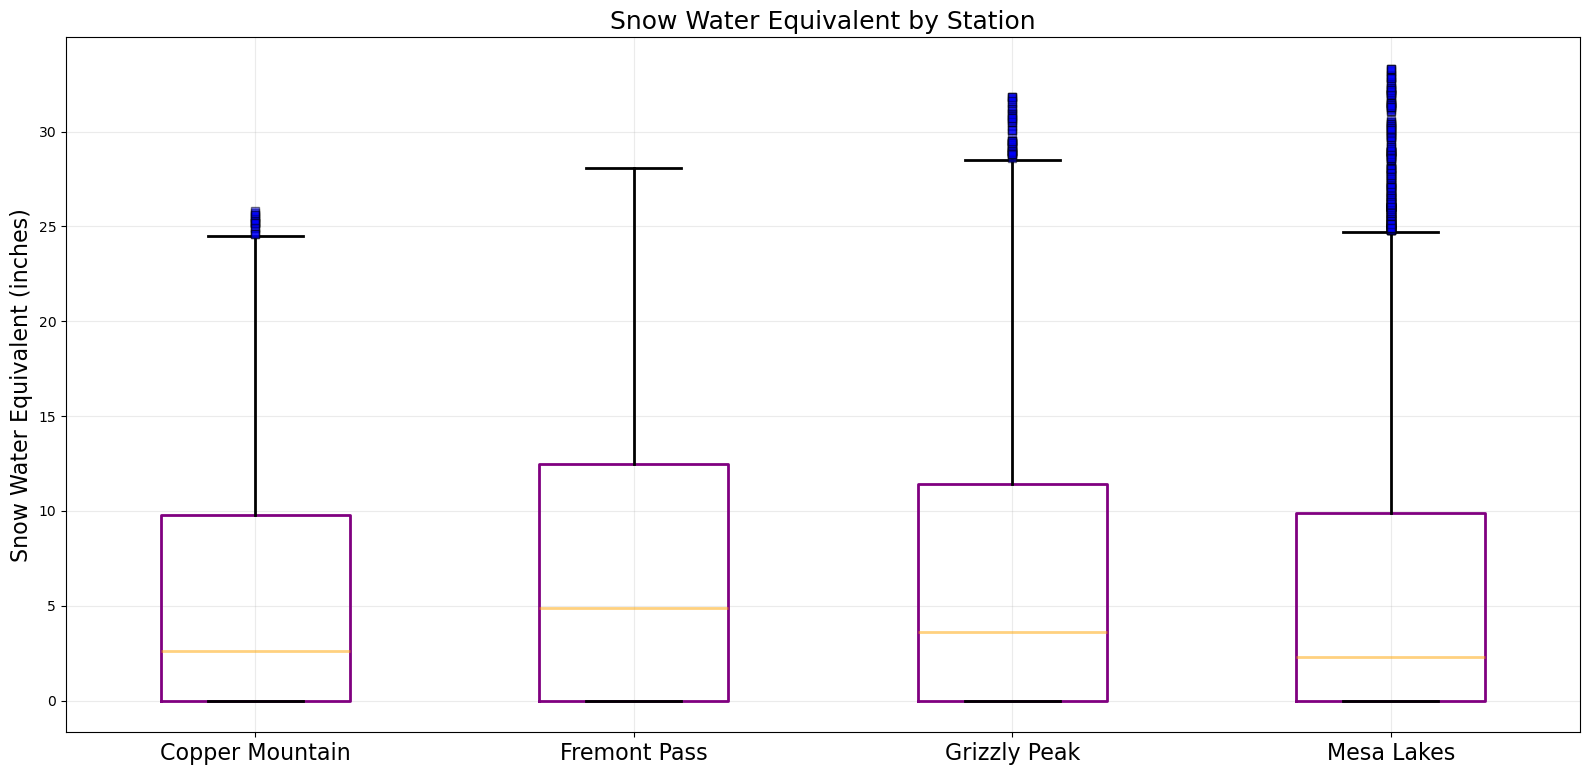

In [25]:
# Plot boxplot by station and save

from pathlib import Path

Path("figures").mkdir(exist_ok=True)

# Initialize figure 
fig, ax = plt.subplots(figsize=(16,8))

bp = recent.boxplot(
    column=["swe"],
    by="station",
    ax=ax,
    widths=[.5, .5, .5, .5],
    return_type="dict"
)

for column in bp:
    
    for box in column['boxes']:
        box.set(color='purple', linewidth=2)
    
    for whisker in column['whiskers']:
        whisker.set(color='black', linewidth=2)

    for cap in column['caps']:
        cap.set(color='black', linewidth=2)

    for median in column['medians']:
        median.set(color='orange', linewidth=2, alpha=0.5)

    for flier in column['fliers']:
        flier.set(
            markerfacecolor='blue',
            linewidth=2,
            marker='s',
            markersize=6,
            alpha=0.5
        )

ax.set_title(
    'Snow Water Equivalent by Station',
    fontsize=18
)

ax.set_ylabel(
    "Snow Water Equivalent (inches)",
    fontsize=16
)

plt.xticks(
    [1, 2, 3, 4],
    [
        "Copper Mountain",
        "Fremont Pass",
        "Grizzly Peak",
        "Mesa Lakes"
    ],
    rotation=0,
    fontsize=16
)

plt.suptitle("")
ax.set_xlabel("")
ax.grid(alpha=0.25)

plt.tight_layout()

fig.savefig(
    "figures/swe_by_station.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
fig.savefig(
    "figures/swe_by_station.pdf",
    bbox_inches="tight"
)

In [28]:
# Summmariz by month and standardize
snow['date'] = pd.to_datetime(snow['date'])

snow_monthly = (
    snow
    .set_index('date')
    .groupby('station')
    .resample('MS')
    .agg(
        swe=('swe', 'mean'),
        precip_increment=('precip_increment', 'sum'),
        precip_accum=('precip_accum', 'last')
    )
    .reset_index()
)

snow_monthly['month_num'] = snow_monthly['date'].dt.month

# monthly SWE climatology by station + calendar month
snow_monthly['swe_mean'] = (
    snow_monthly
    .groupby(['station', 'month_num'])['swe']
    .transform('mean')
)

snow_monthly['swe_std'] = (
    snow_monthly
    .groupby(['station', 'month_num'])['swe']
    .transform('std')
)

# standardized SWE anomaly
snow_monthly['swe_z'] = (
    (snow_monthly['swe'] - snow_monthly['swe_mean'])
    / snow_monthly['swe_std']
)

# neutralize months with almost no SWE variability
snow_monthly.loc[
    snow_monthly['swe_std'] < 0.5,
    'swe_z'
] = 0

In [29]:
snow_monthly[
    ['precip_increment', 'precip_accum']
].describe()

,precip_increment,precip_accum
count,2170.000000,2169.000000
mean,2.493733,17.155002
std,1.418032,10.024677
min,0.000000,0.000000
25%,1.500000,8.400000
50%,2.300000,17.400000
75%,3.300000,24.800000
max,10.500000,50.400000


In [30]:
snow[
    ['date', 'station', 'precip_accum', 'precip_increment']
].head(20)


,date,station,precip_accum,precip_increment
0,1980-07-28,Fremont Pass,24.1,0.0
1,1980-07-29,Fremont Pass,24.1,0.0
2,1980-07-30,Fremont Pass,24.1,0.0
3,1980-07-31,Fremont Pass,24.1,0.0
4,1980-08-01,Fremont Pass,24.1,0.0
5,1980-08-02,Fremont Pass,24.1,0.0
6,1980-08-03,Fremont Pass,24.1,0.0
7,1980-08-04,Fremont Pass,24.1,0.0
8,1980-08-05,Fremont Pass,24.1,0.0
9,1980-08-06,Fremont Pass,24.1,0.0


In [33]:
# Daily dataset
snow.to_parquet(
    r"C:\Users\katel\extreme climate\data\snotel_daily.parquet",
    index=False
)

# Monthly dataset
snow_monthly.to_parquet(
    r"C:\Users\katel\extreme climate\data\snotel_monthly.parquet",
    index=False
)